<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s):
* Calo Ayelén

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

# Traductor Seq2Seq EN→ES — TP Procesamiento de Lenguaje Natural
## 1. Setup y exploración del dataset
## 2. Preprocesamiento
## 3. Modelo Seq2Seq
## 4. Métricas de evaluación
## 5. Experimentos: impacto del número de unidades LSTM
## 6. Ejemplos de traducción
## 7. (Opcional) Estrategias de decodificación
## 8. Conclusiones

In [3]:
# Paso 1: Imports y semillas:
# Se fijan las semillas de NumPy, TensorFlow y Python desde el principio.
# Si no, cuando se compare 128 vs 256 vs 512 unidades no se sabrá si una diferencia es por la arquitectura o por la inicialización aleatoria.


import os, re, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 40
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TF: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Guardado de resultados en Drive.** Se monta Drive al principio para que los pesos y los historiales de cada configuración queden guardados fuera de la sesión de Colab. Si la sesión se desconecta, al volver a ejecutar la notebook los modelos ya entrenados se cargan desde Drive en lugar de reentrenarse.

In [4]:
import json, time
from google.colab import drive

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/tp_traductor'
os.makedirs(SAVE_DIR, exist_ok=True)
print("Archivos guardados:", sorted(os.listdir(SAVE_DIR)))

Mounted at /content/drive
Archivos guardados: ['history_128.json', 'history_256.json', 'history_512.json', 'seq2seq_128.weights.h5', 'seq2seq_256.weights.h5', 'seq2seq_512.weights.h5']


Pares totales: 118964
EN -> mediana=6  p90=10  p95=12  p99=15  max=47
ES -> mediana=6  p90=10  p95=11  p99=15  max=49


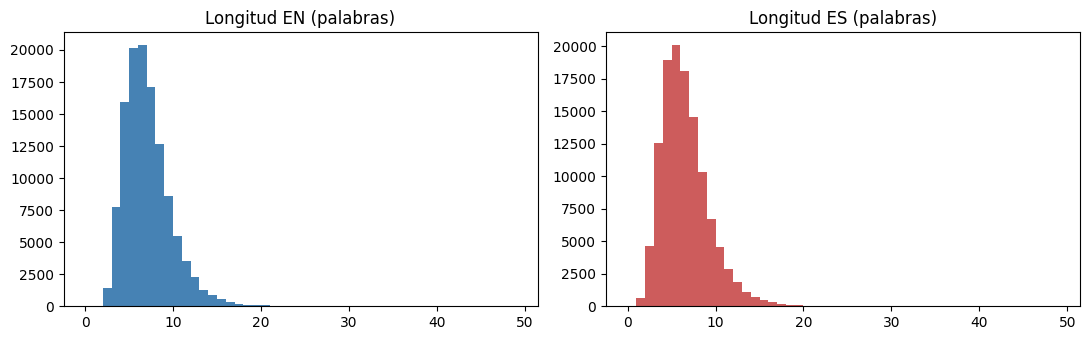

In [6]:
# Descarga del dataset (Tatoeba, inglés \t español)
if not os.path.exists('spa-eng'):
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip")

with open("./spa-eng/spa.txt", encoding="utf-8") as f:
    lines = [l for l in f.read().split("\n") if "\t" in l]

print(f"Pares totales: {len(lines)}")

SEED = 40
rng = np.random.default_rng(SEED)
rng.shuffle(lines)

pairs = [l.split("\t")[:2] for l in lines]

# Longitud en palabras (aproximada: separamos puntuación para contarla como el tokenizer)
def n_words(s):
    return len(re.findall(r"\w+", s.lower()))

len_en = np.array([n_words(en) for en, es in pairs])
len_es = np.array([n_words(es) for en, es in pairs])

for name, arr in [("EN", len_en), ("ES", len_es)]:
    p = np.percentile(arr, [50, 90, 95, 99, 100])
    print(f"{name} -> mediana={p[0]:.0f}  p90={p[1]:.0f}  p95={p[2]:.0f}  p99={p[3]:.0f}  max={p[4]:.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(len_en, bins=range(0, 50), color="steelblue"); ax[0].set_title("Longitud EN (palabras)")
ax[1].hist(len_es, bins=range(0, 50), color="indianred"); ax[1].set_title("Longitud ES (palabras)")
plt.tight_layout(); plt.show()

Los datos están muy concentrados: la mediana es de 6 palabras y el 99% tiene 15 o menos en ambos idiomas. La cola larga (hasta 47–49) son muy pocas oraciones, casi párrafos.

Qué longitud y cuántas oraciones usar

Se porpone filtrar los pares donde ambas oraciones tengan ≤ 20 palabras. Eso conserva más del 99% del dataset y deja afuera sólo los outliers. Los filtramos en vez de truncarlos porque truncar genera pares inconsistentes: el inglés cortado ya no corresponde a la traducción completa.

Cantidad de oraciones. Se porpone arrancar con 60k pares: 6 veces más que en clase y razonable para la sesión de Colab.



In [7]:
# Paso 2a: filtrado y split


MAX_WORDS   = 20       # largo máximo (en palabras) para EN y ES
N_SENTENCES = 60000    # cantidad de pares a usar

# Filtrar por longitud (usamos los conteos ya calculados)
mask = (len_en <= MAX_WORDS) & (len_es <= MAX_WORDS) & (len_en > 0) & (len_es > 0)
filtered = [p for p, keep in zip(pairs, mask) if keep]
print(f"Pares que cumplen el largo: {len(filtered)} de {len(pairs)} "
      f"({100*len(filtered)/len(pairs):.2f}%)")

# Ya estaban mezclados con la semilla, tomamos los primeros N
filtered = filtered[:N_SENTENCES]
en_sentences = [en for en, es in filtered]
es_sentences = [es for en, es in filtered]

# Split 80 / 10 / 10
n       = len(en_sentences)
n_train = int(0.8 * n)
n_val   = int(0.1 * n)

idx_train = slice(0, n_train)
idx_val   = slice(n_train, n_train + n_val)
idx_test  = slice(n_train + n_val, n)

print(f"Train: {n_train} | Val: {n_val} | Test: {n - n_train - n_val}")
for i in range(3):
    print(f"  {en_sentences[i]}  →  {es_sentences[i]}")

Pares que cumplen el largo: 118763 de 118964 (99.83%)
Train: 48000 | Val: 6000 | Test: 6000
  Come here before seven o'clock.  →  Ven aquí antes de las siete.
  Just as we are talking, there was a loud explosion.  →  Justo mientras estamos hablando ha habido una fuerte explosión.
  In the near future, space travel will no longer be just a dream.  →  En un futuro cercano, el viaje espacial dejará de ser un simple sueño.


# Paso 2b: tokenización

Se ajustan 3 puntos con respecto a la clase:

1. <sos> y <eos> con frecuencia real. En vez de agregarlos sueltos al vocabulario, se ajusta el tokenizer sobre las oraciones completas <sos> ... <eos>. Así cada uno aparece 48.000 veces, quedan entre los índices más bajos y nunca los corta el límite de vocabulario. Después, a partir de esa misma oración, se arman las dos secuencias del decoder:

$$\text{decoder_in} = [\texttt{<sos>}, w_1, \dots, w_T] \qquad \text{decoder_out} = [w_1, \dots, w_T, \texttt{<eos>}]$$


2. Token <unk> para palabras fuera del vocabulario. En clase, una palabra fuera de las top-8000 se eliminaba de la secuencia. En el target eso es grave: “compré una guitarra roja” quedaría “compré una roja”, y el modelo aprendería una traducción que no corresponde al inglés. Con oov_token='<unk>' la palabra se reemplaza por <unk> y la alineación se mantiene.

3. Signos de español. Se agregan ¡ a los filtros (clase sólo filtraba ¿) y sacamos < y >, para que no se rompan nuestros tokens especiales.

Por ahora se ajustan los tokenizers sin límite de vocabulario, sólo para medir. Así se podrá elegir el MAX_VOCAB_SIZE viendo qué porcentaje de las ocurrencias de palabras cubre cada tamaño, en vez de fijar 8000 a ojo.

In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer

def add_special(s):
    return '<sos> ' + s + ' <eos>'

en_train = en_sentences[idx_train]
es_train = [add_special(s) for s in es_sentences[idx_train]]

# Tokenizer EN (filtros por defecto: saca puntuación, pasa a minúsculas)
input_tokenizer = Tokenizer(oov_token='<unk>')
input_tokenizer.fit_on_texts(en_train)

# Tokenizer ES: sin '<' '>' en los filtros, con ¿ y ¡
ES_FILTERS = '!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n¿¡'
output_tokenizer = Tokenizer(filters=ES_FILTERS, oov_token='<unk>')
output_tokenizer.fit_on_texts(es_train)

print("Índices especiales ES:",
      {t: output_tokenizer.word_index[t] for t in ['<unk>', '<sos>', '<eos>']})

def coverage(tokenizer, sizes, exclude=()):
    counts = sorted((c for w, c in tokenizer.word_counts.items() if w not in exclude),
                    reverse=True)
    counts = np.array(counts)
    total  = counts.sum()
    print(f"  vocabulario total: {len(counts)} palabras")
    for k in sizes:
        print(f"  top {k:>6}: cubre {100*counts[:k].sum()/total:6.2f}% de las ocurrencias")

sizes = [3000, 5000, 8000, 10000, 15000]
print("\nEN"); coverage(input_tokenizer, sizes)
print("\nES"); coverage(output_tokenizer, sizes, exclude=('<sos>', '<eos>'))

Índices especiales ES: {'<unk>': 1, '<sos>': 2, '<eos>': 3}

EN
  vocabulario total: 9709 palabras
  top   3000: cubre  95.85% de las ocurrencias
  top   5000: cubre  98.09% de las ocurrencias
  top   8000: cubre  99.43% de las ocurrencias
  top  10000: cubre 100.00% de las ocurrencias
  top  15000: cubre 100.00% de las ocurrencias

ES
  vocabulario total: 17459 palabras
  top   3000: cubre  90.14% de las ocurrencias
  top   5000: cubre  93.71% de las ocurrencias
  top   8000: cubre  96.35% de las ocurrencias
  top  10000: cubre  97.43% de las ocurrencias
  top  15000: cubre  99.15% de las ocurrencias


Se eligen EN = 8000 y ES = 10000:

Inglés, 8000: cubre 99.4% de las ocurrencias. Pasar a 10000 sólo suma un 0.6%, que son palabras que aparecen una o dos veces en todo el corpus.
Español, 10000: cubre 97.4%, o sea en promedio un <unk> cada ~38 tokens (aproximadamente uno cada 5 oraciones). Subir a 15000 ganaría un 1.7% más, pero agregaría 5000 salidas al softmax. Son palabras muy raras de las que el modelo, con tan pocos ejemplos, igual no aprendería mucho.


# Paso 2c: secuencias y padding


Para el decoder tokenizamos una sola vez <sos> ... <eos> y desplazamos:

dec_in = seq[:-1] → sin el <eos> final;
dec_out = seq[1:] → sin el <sos> inicial.

Es lo mismo que hacía clase con dos strings, pero garantiza que ambas secuencias estén alineadas token a token.

El padding queda como en clase:

encoder con pre: los ceros van adelante, así el último estado del LSTM corresponde a la última palabra real y no a varios pasos de padding que “diluyen” la memoria;
decoder con post: los ceros van al final, después de <eos>.

In [9]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_EN = 8000
VOCAB_ES = 10000
input_tokenizer.num_words  = VOCAB_EN
output_tokenizer.num_words = VOCAB_ES

def encode(split):
    enc    = input_tokenizer.texts_to_sequences(en_sentences[split])
    es_seq = output_tokenizer.texts_to_sequences([add_special(s) for s in es_sentences[split]])
    dec_in  = [s[:-1] for s in es_seq]
    dec_out = [s[1:]  for s in es_seq]
    return enc, dec_in, dec_out

raw = {name: encode(sl) for name, sl in
       [('train', idx_train), ('val', idx_val), ('test', idx_test)]}

# Largos máximos medidos en tokens reales, sólo sobre train
max_input_len = max(len(s) for s in raw['train'][0])
max_out_len   = max(len(s) for s in raw['train'][1])
print(f"max_input_len={max_input_len}  max_out_len={max_out_len}")

def pad(enc, dec_in, dec_out):
    return (pad_sequences(enc,     maxlen=max_input_len, padding='pre',  truncating='pre'),
            pad_sequences(dec_in,  maxlen=max_out_len,   padding='post', truncating='post'),
            pad_sequences(dec_out, maxlen=max_out_len,   padding='post', truncating='post'))

data = {name: pad(*raw[name]) for name in raw}
for name, (e, di, do) in data.items():
    print(f"{name:5}: enc {e.shape}  dec_in {di.shape}  dec_out {do.shape}")

# Proporción de <unk> en los targets de validación (tokens reales, sin padding)
do_val = data['val'][2]
print(f"\n<unk> en targets de val: {100*np.mean(do_val[do_val > 0] == 1):.2f}%")

# Chequeo de alineación sobre un ejemplo
iw_es = output_tokenizer.index_word
iw_en = input_tokenizer.index_word
e, di, do = (x[0] for x in data['train'])
print("\nEN     :", ' '.join(iw_en[i] for i in e if i > 0))
print("dec_in :", ' '.join(iw_es[i] for i in di if i > 0))
print("dec_out:", ' '.join(iw_es[i] for i in do if i > 0))

max_input_len=20  max_out_len=21
train: enc (48000, 20)  dec_in (48000, 21)  dec_out (48000, 21)
val  : enc (6000, 20)  dec_in (6000, 21)  dec_out (6000, 21)
test : enc (6000, 20)  dec_in (6000, 21)  dec_out (6000, 21)

<unk> en targets de val: 3.75%

EN     : come here before seven o'clock
dec_in : <sos> ven aquí antes de las siete
dec_out: ven aquí antes de las siete <eos>


# Paso 3a: tf.data sin one-hot


Se mezcla train en cada época (clase no lo hacía) y se sube el batch a 128. Con 48k ejemplos aprovecha mejor la GPU: son 375 pasos por época en vez de 750.Se mantiene fijo en todos los experimentos, así no confunde la comparación.

In [10]:
BATCH_SIZE = 128
AUTOTUNE   = tf.data.AUTOTUNE

def make_dataset(enc, dec_in, dec_out, shuffle):
    ds = tf.data.Dataset.from_tensor_slices(((enc, dec_in), dec_out))
    if shuffle:
        ds = ds.shuffle(len(enc), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(*data['train'], shuffle=True)
val_ds   = make_dataset(*data['val'],   shuffle=False)

(x_enc, x_dec), y = next(iter(train_ds))
print(x_enc.shape, x_dec.shape, y.shape, y.dtype)

(128, 20) (128, 21) (128, 21) <dtype: 'int32'>


# Paso 3b: el modelo como función de n_units

Cambios aplicados:

1. Dimensión de embedding fija. En clase el embedding del decoder usaba output_dim=n_units. Si comparamos 128 vs 512 unidades así, también cambiaría el embedding y no podríamos separar los dos efectos. Se fija en EMB_DIM = 128 para ambos idiomas.

2. Embedding del encoder entrenable por defecto. La función acepta opcionalmente una matriz preentrenada (como el GloVe 50d congelado de clase). Se propone que la línea base sea con embeddings entrenables en ambos idiomas, y dejar GloVe en inglés y fastText en español para la actividad opcional. Así esa comparación también queda limpia.

In [11]:
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.initializers import Constant

EMB_DIM = 128

def build_seq2seq(n_units, emb_dim=EMB_DIM, dropout=0.3, enc_emb_matrix=None):
    # ----- Encoder -----
    enc_inputs = Input(shape=(max_input_len,), name='encoder_inputs')
    if enc_emb_matrix is None:
        enc_emb_layer = Embedding(VOCAB_EN, emb_dim, name='encoder_embedding')
    else:
        enc_emb_layer = Embedding(VOCAB_EN, enc_emb_matrix.shape[1],
                                  embeddings_initializer=Constant(enc_emb_matrix),
                                  trainable=False, name='encoder_embedding')
    x = Dropout(dropout, name='encoder_dropout')(enc_emb_layer(enc_inputs))
    enc_lstm = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm(x)

    # ----- Decoder -----
    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')
    dec_emb_layer = Embedding(VOCAB_ES, emb_dim, name='decoder_embedding')
    y = Dropout(dropout, name='decoder_dropout')(dec_emb_layer(dec_inputs))
    dec_lstm = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm')
    y, _, _ = dec_lstm(y, initial_state=[state_h, state_c])
    dec_dense = Dense(VOCAB_ES, activation='softmax', name='decoder_dense')
    outputs = dec_dense(y)

    model  = Model([enc_inputs, dec_inputs], outputs, name=f'seq2seq_{n_units}')
    layers = dict(enc_inputs=enc_inputs, enc_emb=enc_emb_layer, enc_lstm=enc_lstm,
                  dec_emb=dec_emb_layer, dec_lstm=dec_lstm, dec_dense=dec_dense)
    return model, layers

# Cuántos parámetros tiene cada configuración que vamos a comparar
for u in [128, 256, 512]:
    m, _ = build_seq2seq(u)
    lstm_p  = m.get_layer('encoder_lstm').count_params() + m.get_layer('decoder_lstm').count_params()
    dense_p = m.get_layer('decoder_dense').count_params()
    print(f"n_units={u:>3}: total={m.count_params():>10,}  LSTMs={lstm_p:>9,}  Dense={dense_p:>9,}")
tf.keras.backend.clear_session()

n_units=128: total= 3,857,168  LSTMs=  263,168  Dense=1,290,000
n_units=256: total= 5,662,480  LSTMs=  788,480  Dense=2,570,000
n_units=512: total=10,059,536  LSTMs=2,625,536  Dense=5,130,000


# Paso 4: loss y accuracy enmascarados

In [12]:
print(f"Proporción de padding en targets de val: {100*np.mean(data['val'][2] == 0):.1f}%")

Proporción de padding en targets de val: 66.3%


In [13]:
def masked_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)   # (batch, T)
    mask = tf.cast(y_true != 0, loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)

def masked_acc(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    y_hat  = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
    mask   = tf.cast(y_true != 0, tf.float32)
    match  = tf.cast(y_hat == y_true, tf.float32)
    return tf.reduce_sum(match * mask) / tf.reduce_sum(mask)

# Paso 5a: función de entrenamiento

Se usan los mismos callbacks que en clase, pero ahora se monitorean la loss enmascarada de validación. Se sube el learning rate inicial a 1e-3 porque duplicamos el batch, y ReduceLROnPlateau lo baja si se estanca. También se guarda el tiempo y el historial de cada corrida en un diccionario, para la comparación final.

In [14]:
import time
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

results = {}   # n_units -> dict(model, layers, history, tiempo)

def train_config(n_units, epochs=30, lr=1e-3, **model_kwargs):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)                      # misma inicialización relativa en cada corrida

    model, layers = build_seq2seq(n_units, **model_kwargs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss=masked_loss, metrics=[masked_acc])

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ]

    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)
    elapsed = time.time() - t0

    best = int(np.argmin(hist.history['val_loss']))
    print(f"\n[n_units={n_units}] mejor época: {best+1} | "
          f"val_loss={hist.history['val_loss'][best]:.3f} "
          f"(perplejidad {np.exp(hist.history['val_loss'][best]):.1f}) | "
          f"val_acc={hist.history['val_masked_acc'][best]:.3f} | "
          f"tiempo: {elapsed/60:.1f} min")

    results[n_units] = dict(model=model, layers=layers, history=hist.history, time=elapsed)
    return model, layers

**Guardar y cargar corridas.** Cada configuración se guarda en Drive con los pesos (`seq2seq_<n>.weights.h5`) y el historial con el tiempo de entrenamiento (`history_<n>.json`). Para cargar un modelo se reconstruye la arquitectura con `build_seq2seq` y se le asignan los pesos; esto funciona porque el preprocesamiento usa semillas fijas y produce exactamente el mismo vocabulario en cada ejecución.

In [15]:
def save_run(u):
    r = results[u]
    r['model'].save_weights(f'{SAVE_DIR}/seq2seq_{u}.weights.h5')
    with open(f'{SAVE_DIR}/history_{u}.json', 'w') as f:
        json.dump({'history': {k: [float(x) for x in v] for k, v in r['history'].items()},
                   'time': r['time']}, f)
    print(f"Guardado n_units={u}")

def load_run(u):
    model, layers = build_seq2seq(u)
    model.load_weights(f'{SAVE_DIR}/seq2seq_{u}.weights.h5')
    model.compile(loss=masked_loss, metrics=[masked_acc])
    with open(f'{SAVE_DIR}/history_{u}.json') as f:
        d = json.load(f)
    results[u] = dict(model=model, layers=layers, history=d['history'], time=d['time'])
    print(f"Cargado n_units={u}")

> **Importante si se reinicia la sesión:** las celdas de entrenamiento que siguen quedan con sus salidas como registro de cómo se entrenó cada modelo. Si la sesión se reinicia, **no hace falta volver a ejecutarlas**: ejecutar todo hasta la celda anterior y saltar directamente a la celda *"Carga desde Drive"* del Paso 5c.

In [ ]:
#Se ejecutan los modelos
model_128, layers_128 = train_config(128)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - loss: 5.9033 - masked_acc: 0.1628 - val_loss: 5.2871 - val_masked_acc: 0.1983 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - loss: 5.1950 - masked_acc: 0.2095 - val_loss: 4.9264 - val_masked_acc: 0.2259 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - loss: 4.8648 - masked_acc: 0.2378 - val_loss: 4.6641 - val_masked_acc: 0.2513 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - loss: 4.5815 - masked_acc: 0.2690 - val_loss: 4.4250 - val_masked_acc: 0.2791 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - loss: 4.3573 - masked_acc: 0.2878 - val_loss: 4.2625 - val_masked_acc: 0.2887 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - loss: 4.1640 - masked_acc: 0.3060 - val_loss: 4.0958 - val_masked_acc: 0.3114 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/ste

Lectura de la corrida de 128 unidades

El modelo no terminó de entrenar. La mejor época fue la última (30), ReduceLROnPlateau nunca se activó (el LR quedó en 0.001) y el val_loss seguía bajando unas 0.02 por época. Cortó el tope de épocas, no el early stopping.

Esto importa para el experimento. Si se comparan 128 vs 256 vs 512 con un tope de 30 épocas, los modelos grandes (que suelen converger en menos épocas) quedarían favorecidos por algo que no es su capacidad. Cada configuración tiene que llegar a su propio óptimo, y el criterio de parada lo tiene que decidir el early stopping, no el contador.

Aparece la brecha train/val. Train está en 2.04 y val en 2.84. Va creciendo (en la época 10 era 3.55 vs 3.65), pero mientras val siga bajando no hay sobreajuste dañino todavía.

Cómo leer el 48%. Es accuracy por token con teacher forcing: el decoder recibe siempre la palabra correcta anterior y sólo tiene que adivinar la siguiente. En inferencia real va a recibir sus propias predicciones y los errores se acumulan, así que la calidad de traducción va a ser peor de lo que sugiere este número. Por eso se mide BLEU con decodificación greedy sobre el test.

La perplejidad de 17 significa que, en promedio, el modelo duda como si eligiera entre ~17 palabras igualmente probables (de 10000 posibles). No está mal para un LSTM sin atención.

In [ ]:
# Paso 5b: continuar el entrenamiento sin empezar de cero

def summarize(n_units):
    h = results[n_units]['history']
    best = int(np.argmin(h['val_loss']))
    print(f"[n_units={n_units}] mejor época: {best+1}/{len(h['val_loss'])} | "
          f"val_loss={h['val_loss'][best]:.3f} (perplejidad {np.exp(h['val_loss'][best]):.1f}) | "
          f"val_acc={h['val_masked_acc'][best]:.3f} | "
          f"tiempo total: {results[n_units]['time']/60:.1f} min")

def continue_training(n_units, total_epochs=60):
    r     = results[n_units]
    done  = len(r['history']['loss'])
    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ]
    t0 = time.time()
    hist = r['model'].fit(train_ds, validation_data=val_ds,
                          initial_epoch=done, epochs=total_epochs, callbacks=callbacks)
    r['time'] += time.time() - t0
    for k, v in hist.history.items():                 # concatenamos el historial
        r['history'].setdefault(k, []).extend(v)
    summarize(n_units)

continue_training(128, total_epochs=60)
save_run(128)

Epoch 31/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - loss: 1.9889 - masked_acc: 0.5654 - val_loss: 2.8344 - val_masked_acc: 0.4854 - learning_rate: 0.0010
Epoch 32/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - loss: 1.9468 - masked_acc: 0.5708 - val_loss: 2.8155 - val_masked_acc: 0.4896 - learning_rate: 0.0010
Epoch 33/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - loss: 1.9071 - masked_acc: 0.5777 - val_loss: 2.8052 - val_masked_acc: 0.4915 - learning_rate: 0.0010
Epoch 34/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - loss: 1.8675 - masked_acc: 0.5845 - val_loss: 2.7941 - val_masked_acc: 0.4944 - learning_rate: 0.0010
Epoch 35/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - loss: 1.8306 - masked_acc: 0.5914 - val_loss: 2.7923 - val_masked_acc: 0.4966 - learning_rate: 0.0010
Epoch 36/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - loss: 1.7936 - masked_acc: 0.5974 - val_loss: 2.7818 - val_masked_acc: 0.4981 - learning_rate: 0.0010
Epoch 37/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 4

Lectura de las 60 épocas de 128 unidades

El val_loss se aplanó. Entre las épocas 30 y 45 bajó de 2.84 a 2.73. Entre la 45 y la 60, apenas a 2.70. Formalmente la mejor época sigue siendo la última, pero en las últimas 10 épocas la mejora fue de ~0.01. Prácticamente llegó a su techo. Con más épocas y el LR reducido ganaríamos centésimas, así que no vale la pena el tiempo.

El sobreajuste ya es claro. Train bajó a 1.21 y val quedó en 2.70: la brecha pasó de ~0.1 en la época 10 a ~1.5. Con 3.8M de parámetros y 48k oraciones, el modelo memoriza train más rápido de lo que generaliza.

Señal típica de sobreajuste: loss y accuracy de val se separan. Desde la época ~45 el val_masked_acc sigue subiendo (0.515 → 0.532) mientras el val_loss casi no se mueve. Eso quiere decir que el modelo acierta un poco más seguido, pero cuando se equivoca lo hace con más confianza. La cross-entropy castiga mucho asignar probabilidad baja a la palabra correcta, y eso compensa los aciertos nuevos.

Resultado de 128 unidades: val_loss 2.704, perplejidad 14.9, val_acc 53.2%, 18 minutos.

In [ ]:
# Se entrena 256 unidades con el mismo tope de 60 épocas
model_256, layers_256 = train_config(256, epochs=60)
save_run(256)

Epoch 1/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 74ms/step - loss: 5.7148 - masked_acc: 0.1798 - val_loss: 5.0637 - val_masked_acc: 0.2128 - learning_rate: 0.0010
Epoch 2/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 73ms/step - loss: 4.9670 - masked_acc: 0.2241 - val_loss: 4.7186 - val_masked_acc: 0.2374 - learning_rate: 0.0010
Epoch 3/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - loss: 4.6326 - masked_acc: 0.2525 - val_loss: 4.4355 - val_masked_acc: 0.2695 - learning_rate: 0.0010
Epoch 4/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - loss: 4.3196 - masked_acc: 0.2846 - val_loss: 4.1893 - val_masked_acc: 0.2953 - learning_rate: 0.0010
Epoch 5/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 69ms/step - loss: 4.0588 - masked_acc: 0.3113 - val_loss: 3.9833 - val_masked_acc: 0.3177 - learning_rate: 0.0010
Epoch 6/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - loss: 3.8155 - masked_acc: 0.3358 - val_loss: 3.8064 - val_masked_acc: 0.3402 - learning_rate: 0.0010
Epoch 7/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 69ms/ste

**Lectura de la corrida de 256 unidades**

Esta vez el entrenamiento terminó por early stopping y no por el tope de épocas. El val_loss tocó su mínimo en la época 40 (2.732); ReduceLROnPlateau bajó el learning rate tres veces (épocas 38, 42 y 44, de 1e-3 a 1.25e-4) sin lograr mejoras adicionales, y el entrenamiento se detuvo en la época 44 restaurando los pesos de la época 40.

Convergió más rápido en épocas que el modelo de 128. Llegó a un val_loss de ~2.74 en la época 33, mientras que el de 128 necesitó unas 45 épocas para alcanzar ese valor. Con más capacidad, cada paso de gradiente reduce más la loss.

Pero no generalizó mejor. El val_loss final (2.732, perplejidad 15.4) es prácticamente igual al de 128 (2.704, perplejidad 14.9), y el val_acc también (53.3% vs 53.2%). Con una sola corrida por configuración, una diferencia de 0.03 en la loss está dentro de lo que podría cambiar con otra semilla, por lo que en validación ambos modelos están empatados.

Lo que sí cambió es cómo usa la capacidad extra. Comparando ambos modelos en el mismo val_loss (~2.73), el de 128 tenía un train_loss de 1.56 (época 44) y el de 256 de 1.09 (época 40). Es decir, para generalizar lo mismo, el modelo de 256 ajusta mucho más el conjunto de entrenamiento: las unidades adicionales se destinan a memorizar las 48k oraciones de train, no a mejorar la traducción de oraciones nuevas. La brecha val−train en la mejor época pasa de 1.50 (128) a 1.65 (256).

En costo, cada época tarda ~26 s frente a ~18 s del modelo de 128 (×1.45). El aumento es menor que el de parámetros porque una parte importante del cómputo es la capa Dense de 10000 salidas, que crece linealmente con el número de unidades. Como converge en menos épocas, el tiempo total resulta similar (19.6 vs 18.3 min).

Hipótesis: con este volumen de datos, el cuello de botella no es la capacidad recurrente. Por un lado, la única regularización es el dropout sobre los embeddings. Por otro, la arquitectura comprime toda la oración de entrada en un único vector de contexto (h, c) de tamaño fijo, sin atención: más unidades agrandan ese vector, pero no le dan al decoder acceso a la entrada palabra por palabra. La corrida de 512 unidades permite poner a prueba esta hipótesis: si se cumple, debería converger en todavía menos épocas, sobreajustar más y no mejorar el val_loss.

In [14]:
# Se entrena 512 unidades con el mismo tope de 60 épocas
model_512, layers_512 = train_config(512, epochs=60)
save_run(512)

Epoch 1/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 48s 105ms/step - loss: 5.5621 - masked_acc: 0.1898 - val_loss: 4.9073 - val_masked_acc: 0.2199 - learning_rate: 0.0010
Epoch 2/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 4.7319 - masked_acc: 0.2450 - val_loss: 4.4357 - val_masked_acc: 0.2664 - learning_rate: 0.0010
Epoch 3/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 113ms/step - loss: 4.2736 - masked_acc: 0.2855 - val_loss: 4.0966 - val_masked_acc: 0.3022 - learning_rate: 0.0010
Epoch 4/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - loss: 3.9150 - masked_acc: 0.3201 - val_loss: 3.8578 - val_masked_acc: 0.3294 - learning_rate: 0.0010
Epoch 5/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - loss: 3.6234 - masked_acc: 0.3497 - val_loss: 3.6603 - val_masked_acc: 0.3538 - learning_rate: 0.0010
Epoch 6/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 112ms/step - loss: 3.3751 - masked_acc: 0.3757 - val_loss: 3.5103 - val_masked_acc: 0.3766 - learning_rate: 0.0010
Epoch 7/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 11

**Lectura de la corrida de 512 unidades**

El entrenamiento terminó por early stopping en la época 31, restaurando los pesos de la época 27 (val_loss 2.835, perplejidad 17.0, val_acc 51.7%). ReduceLROnPlateau redujo el learning rate cuatro veces (épocas 23, 26, 29 y 31) sin lograr bajar el val_loss en forma apreciable: desde la época ~19 el val_loss quedó prácticamente estancado alrededor de 2.84–2.86.

Se confirma lo anticipado en la lectura de 256 unidades:

- Converge en menos épocas. La mejor época fue la 27, frente a la 40 de 256 y la 60 de 128. En las primeras épocas aprende claramente más rápido: en la época 4 el val_loss era 3.86, contra 4.19 (256) y 4.43 (128).
- Sobreajusta más. En la mejor época, el train_loss es 1.06 y la brecha val−train es 1.77, la mayor de las tres configuraciones. Comparando los modelos cuando su val_loss pasa por ~2.86, el de 512 tenía un train_loss de 1.58 (época 19), contra 2.00 del de 256 (época 21) y 2.08 del de 128 (época 29): para el mismo nivel de generalización, el modelo grande ajusta mucho más el conjunto de entrenamiento.
- No mejora la generalización: la empeora. Es la única configuración claramente peor que las otras en validación (+0.13 de val_loss y −1.5 puntos de val_acc respecto de 128).

Para verificar que esta diferencia no se debe a la aleatoriedad del entrenamiento, el modelo de 512 se entrenó dos veces. La primera corrida obtuvo un val_loss de 2.858 y la segunda de 2.835: una variación de 0.02 entre corridas de la misma configuración, bastante menor que la diferencia de ~0.13 con el modelo de 128. Se reportan los resultados de la segunda corrida, que es la que conserva el historial completo.

En costo, cada época tarda ~42 s, 2.3 veces lo que una época del modelo de 128. El tiempo total (23.2 min) es comparable al de las otras configuraciones sólo porque el early stopping corta antes.

In [19]:
# Guarga resultados anteriores en el Drive
from google.colab import files

uploaded = files.upload()   # elegí history_128.json e history_256.json

for name, content in uploaded.items():
    u = 128 if '128' in name else 256
    with open(f'{SAVE_DIR}/history_{u}.json', 'wb') as f:
        f.write(content)
    print(f"Guardado history_{u}.json en Drive")

Saving history_128.json to history_128.json
Saving history_256.json to history_256.json
Guardado history_128.json en Drive
Guardado history_256.json en Drive


# Paso 5c: carga desde Drive

Si la sesión se reinició, esta celda recupera desde Drive los modelos que no están en memoria. Si los entrenamientos se ejecutaron en esta misma sesión, no recarga nada. Luego evalúa cada modelo sobre validación como control: el `val_loss` debe coincidir con el de la mejor época del historial.

In [16]:
CONFIGS = [128, 256, 512]

if 'results' not in globals():
    results = {}
for u in CONFIGS:
    if u not in results:
        load_run(u)

for u in CONFIGS:
    val_loss, val_acc = results[u]['model'].evaluate(val_ds, verbose=0)
    print(f"n_units={u}: val_loss={val_loss:.3f}  val_acc={val_acc:.3f}  "
          f"(perplejidad {np.exp(val_loss):.1f})")

Cargado n_units=128
Cargado n_units=256
Cargado n_units=512
n_units=128: val_loss=2.704  val_acc=0.532  (perplejidad 14.9)
n_units=256: val_loss=2.732  val_acc=0.533  (perplejidad 15.4)
n_units=512: val_loss=2.835  val_acc=0.517  (perplejidad 17.0)


# Paso 5d: comparación de configuraciones

In [18]:
import pandas as pd

rows = []
for u in CONFIGS:
    h = results[u]['history']
    best = int(np.argmin(h['val_loss']))
    rows.append({
        'n_units':           u,
        'parámetros':        results[u]['model'].count_params(),
        'épocas':            len(h['val_loss']),
        'mejor época':       best + 1,
        'train_loss (mejor)': h['loss'][best],
        'val_loss (mejor)':  h['val_loss'][best],
        'perplejidad val':   np.exp(h['val_loss'][best]),
        'val_acc (mejor)':   h['val_masked_acc'][best],
        'brecha val-train':  h['val_loss'][best] - h['loss'][best],
        'tiempo (min)':      results[u]['time'] / 60,
    })
comparison = pd.DataFrame(rows).set_index('n_units')
comparison.style.format({'parámetros': '{:,.0f}', 'train_loss (mejor)': '{:.3f}',
                         'val_loss (mejor)': '{:.3f}', 'perplejidad val': '{:.1f}',
                         'val_acc (mejor)': '{:.3f}', 'brecha val-train': '{:.3f}',
                         'tiempo (min)': '{:.1f}'})

,parámetros,épocas,mejor época,train_loss (mejor),val_loss (mejor),perplejidad val,val_acc (mejor),brecha val-train,tiempo (min)
n_units,,,,,,,,,
128,"3,857,168",60,60,1.208,2.704,14.9,0.532,1.496,18.3
256,"5,662,480",44,40,1.087,2.732,15.4,0.533,1.645,19.6
512,"10,059,536",31,27,1.065,2.835,17.0,0.517,1.770,23.2


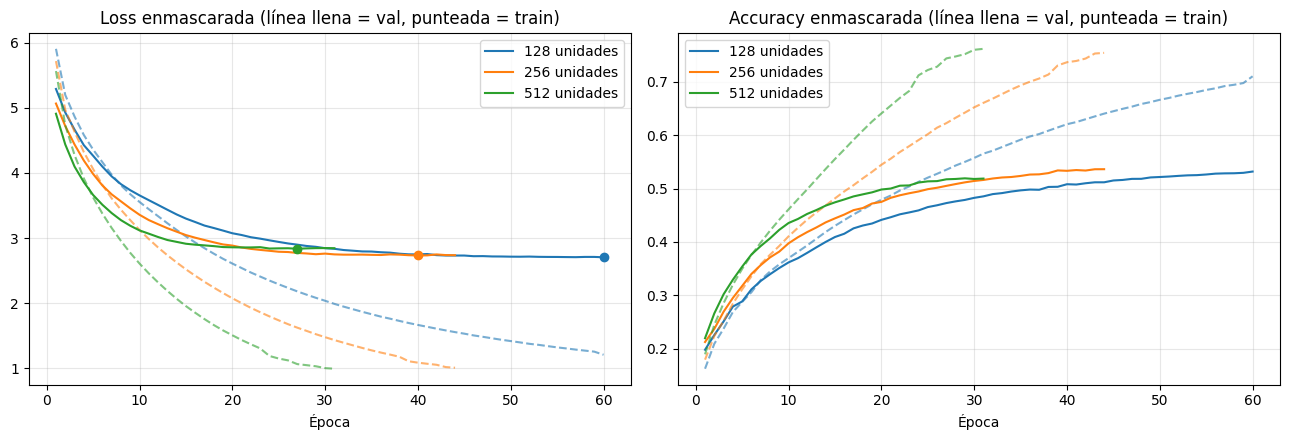

In [19]:
colors = {128: 'tab:blue', 256: 'tab:orange', 512: 'tab:green'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for u in CONFIGS:
    h = results[u]['history']
    ep = range(1, len(h['loss']) + 1)
    ax[0].plot(ep, h['loss'],     '--', color=colors[u], alpha=0.6)
    ax[0].plot(ep, h['val_loss'], '-',  color=colors[u], label=f'{u} unidades')
    ax[1].plot(ep, h['masked_acc'],     '--', color=colors[u], alpha=0.6)
    ax[1].plot(ep, h['val_masked_acc'], '-',  color=colors[u], label=f'{u} unidades')
    best = int(np.argmin(h['val_loss']))
    ax[0].scatter(best + 1, h['val_loss'][best], color=colors[u], zorder=3)

ax[0].set_title('Loss enmascarada (línea llena = val, punteada = train)')
ax[1].set_title('Accuracy enmascarada (línea llena = val, punteada = train)')
for a in ax:
    a.set_xlabel('Época'); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Comparación de configuraciones**

Las tres configuraciones comparten todo excepto el número de unidades de los LSTM.

Más unidades implican convergencia más rápida pero a un piso más alto. Las curvas de validación se cruzan: durante las primeras ~20 épocas el modelo de 512 tiene el val_loss más bajo, pero se estanca en ~2.85 mientras los de 256 y 128 siguen bajando y lo superan. Comparar los modelos a igual número de épocas (por ejemplo, con el tope de 30 que se usaba en clase) habría llevado a la conclusión opuesta.

La capacidad adicional se destina a memorizar. Las curvas de entrenamiento se separan en abanico: cuanto más grande el modelo, más rápido baja el train_loss, mientras que las de validación quedan agrupadas entre 2.70 y 2.85. La brecha val−train en la mejor época crece con el tamaño (1.50 → 1.65 → 1.77). Lo mismo se observa en el accuracy: el train accuracy de 512 llega al 76%, pero las tres configuraciones se estancan entre 52% y 53% en validación. Los escalones en las curvas de entrenamiento coinciden con las reducciones del learning rate, que mejoran el ajuste a train sin trasladarse a validación.

El costo no se compensa. Pasar de 128 a 512 unidades multiplica los parámetros por 2.6 (de 3.9M a 10.1M), los de las capas recurrentes por 10 y el tiempo por época por 2.3, a cambio de un modelo que generaliza peor.

Conclusión. Con 48k pares de entrenamiento, el número de unidades recurrentes no es el factor limitante del desempeño. El modelo de 128 unidades obtiene el mejor val_loss con el menor costo, y el de 256 queda prácticamente empatado. Los límites están en otro lado:

- Regularización: la única es el dropout sobre los embeddings. Agregar dropout dentro de los LSTM, regularización L2 o más datos de entrenamiento probablemente beneficiaría más a los modelos grandes.
- Arquitectura: el encoder comprime toda la oración de entrada en un único vector (h, c) de tamaño fijo, y el decoder no puede volver a consultar la entrada. Aumentar las unidades agranda ese vector, pero no resuelve esta limitación; un mecanismo de atención sí lo haría.

Estas conclusiones se basan en la loss y el accuracy por token con teacher forcing. La evaluación con BLEU sobre el conjunto de test, decodificando sin teacher forcing, permite verificar si el mismo orden se mantiene en la calidad real de las traducciones.

# Paso 6: inferencia

Se decodifica **en batch**: 256 oraciones a la vez, todas avanzando un token por paso.

La lógica greedy es la misma que en clase: en cada paso se elige la palabra más probable,y se realimenta como entrada del paso siguiente. Un vector `done` marca qué oraciones ya emitieron `<eos>` para no seguir agregándoles palabras.

In [20]:
SOS = output_tokenizer.word_index['<sos>']
EOS = output_tokenizer.word_index['<eos>']

def build_inference(layers, n_units):
    # Encoder: devuelve los estados finales (el dropout no actúa en inferencia)
    enc_emb = layers['enc_emb'](layers['enc_inputs'])
    _, h, c = layers['enc_lstm'](enc_emb)
    encoder_model = Model(layers['enc_inputs'], [h, c])

    # Decoder de un paso: (token anterior, h, c) -> (probs, h', c')
    tok_in = Input(shape=(1,))
    h_in   = Input(shape=(n_units,))
    c_in   = Input(shape=(n_units,))
    x = layers['dec_emb'](tok_in)
    x, h_out, c_out = layers['dec_lstm'](x, initial_state=[h_in, c_in])
    probs = layers['dec_dense'](x)
    decoder_model = Model([tok_in, h_in, c_in], [probs, h_out, c_out])
    return encoder_model, decoder_model

def greedy_decode(encoder_model, decoder_model, enc_seqs, batch_size=256):
    all_out = []
    for start in range(0, len(enc_seqs), batch_size):
        x = enc_seqs[start:start + batch_size]
        b = len(x)
        h, c = encoder_model(x, training=False)
        tok  = tf.constant(np.full((b, 1), SOS), dtype=tf.int32)   # <-- tensor, no array
        done = np.zeros(b, dtype=bool)
        out  = np.zeros((b, max_out_len), dtype=int)
        for t in range(max_out_len):
            probs, h, c = decoder_model([tok, h, c], training=False)
            nxt = np.argmax(probs.numpy()[:, 0, :], axis=-1)
            nxt[done] = 0                      # las terminadas sólo agregan padding
            out[:, t] = nxt
            done |= (nxt == EOS)
            tok = tf.constant(nxt[:, None], dtype=tf.int32)        # <-- ídem en cada paso
            if done.all():
                break
        all_out.append(out)
    return np.concatenate(all_out)

def ids_to_text(ids):
    words = []
    for i in ids:
        if i == EOS: break
        if i > 0: words.append(iw_es[i])
    return ' '.join(words)

def translate(texts, n_units):
    enc_m, dec_m = results[n_units]['inference']
    seqs = pad_sequences(input_tokenizer.texts_to_sequences(texts),
                         maxlen=max_input_len, padding='pre', truncating='pre')
    return [ids_to_text(o) for o in greedy_decode(enc_m, dec_m, seqs)]

for u in CONFIGS:
    results[u]['inference'] = build_inference(results[u]['layers'], u)

Prueba rápida con las mismas cuatro frases que se usaron en clase, para comparar directamente con el modelo original.

In [21]:
tests = ["My mother says hi.", "Where is the train station?",
         "I love learning languages.", "Can you help me?"]
for u in CONFIGS:
    print(f"\n--- n_units={u} ---")
    for en, es in zip(tests, translate(tests, u)):
        print(f"{en:30} → {es}")


--- n_units=128 ---
My mother says hi.             → mi madre está diciendo la cocina
Where is the train station?    → dónde está el tren siguiente
I love learning languages.     → creo que <unk> son <unk>
Can you help me?               → puedes ayudarme

--- n_units=256 ---
My mother says hi.             → mi madre sabe mi madre
Where is the train station?    → dónde está la estación de tren
I love learning languages.     → a menudo <unk> historia
Can you help me?               → me puedes ayudar

--- n_units=512 ---
My mother says hi.             → a quién le gusta la verdad
Where is the train station?    → dónde está el tren de la escuela
I love learning languages.     → me encanta estudiar chino
Can you help me?               → puedes ayudarme


Ahora las traducciones están relacionadas con la entrada, y dos de las cuatro frases salen bien en al menos un modelo.

Dos patrones conectan con lo que vimos en las curvas:

* El <unk> como respuesta “segura”. El 3.75% de los tokens de los targets son <unk>, así que el modelo aprendió que es una predicción razonable cuando duda. Ante palabras menos frecuentes como learning o languages, lo prefiere antes que arriesgar una palabra concreta.
* 512 suena más natural pero es menos fiel. Coincide con el sobreajuste: un decoder que memorizó mucho del train funciona como un modelo de lenguaje que genera frases plausibles del corpus (“me encanta estudiar chino” seguramente aparece casi igual en train), aunque no correspondan a la entrada.

# Paso 7: BLEU sobre el test

BLEU compara cada traducción con la de referencia contando cuántos n-gramas (secuencias de 1 a 4 palabras) coinciden. Para cada $n$ calcula una precisión modificada $p_n$: qué fracción de los n-gramas generados aparece en la referencia, sin contar más veces de las que aparece allí (así no se premia repetir “la la la”). Combina las cuatro con una media geométrica y penaliza las traducciones demasiado cortas:

$$\text{BLEU} = \text{BP} \cdot \exp\left(\frac{1}{4}\sum_{n=1}^{4} \log p_n\right), \qquad \text{BP} = \min\left(1,\; e^{\,1 - r/c}\right)$$

donde $c$ es el largo total de las traducciones generadas y $r$ el de las referencias. Sin la penalización $\text{BP}$, un modelo que emitiera sólo palabras seguras (“el”, “de”) tendría precisión alta. Va de 0 a 100. Se calcula a nivel de corpus, sumando conteos sobre las 6000 oraciones, porque a nivel de oración individual es muy ruidoso.

Detalles de cómo se mida:

* Sin teacher forcing: decodificación greedy real, cada modelo con sus propias predicciones.
* Referencias normalizadas igual que las predicciones (minúsculas, sin puntuación), pero sin recortar el vocabulario. Si el modelo emite <unk> donde la referencia dice “idiomas”, cuenta como error.
* BLEU por longitud de la oración de entrada. Así ponemos a prueba la hipótesis del vector de contexto fijo: si tiene razón, el BLEU debería caer en las oraciones largas.

In [22]:
!pip install -q sacrebleu
import sacrebleu
from tensorflow.keras.preprocessing.text import text_to_word_sequence

# Referencias: mismo preprocesamiento que las predicciones (minúsculas, sin puntuación)
test_es  = es_sentences[idx_test]
refs     = [' '.join(text_to_word_sequence(s, filters=ES_FILTERS)) for s in test_es]
enc_test = data['test'][0]
src_len  = (enc_test > 0).sum(axis=1)          # largo de cada oración de entrada (tokens)

# Traducir las 6000 oraciones con cada modelo
preds = {}
for u in CONFIGS:
    enc_m, dec_m = results[u]['inference']
    preds[u] = [ids_to_text(o) for o in greedy_decode(enc_m, dec_m, enc_test)]

def bleu(hyps, refs_):
    return sacrebleu.corpus_bleu(hyps, [refs_], tokenize='none').score

buckets = [('1-5', 1, 5), ('6-10', 6, 10), ('11+', 11, 99)]
for name, lo, hi in buckets:
    print(f"Oraciones de {name:>4} palabras: {np.sum((src_len >= lo) & (src_len <= hi))}")

rows = []
for u in CONFIGS:
    row = {'n_units': u, 'BLEU test': bleu(preds[u], refs)}
    for name, lo, hi in buckets:
        idx = np.where((src_len >= lo) & (src_len <= hi))[0]
        row[f'BLEU {name}'] = bleu([preds[u][i] for i in idx], [refs[i] for i in idx])
    words = [w for p in preds[u] for w in p.split()]
    row['% <unk> generado'] = 100 * np.mean([w == '<unk>' for w in words])
    row['largo medio pred'] = np.mean([len(p.split()) for p in preds[u]])
    rows.append(row)

print(f"Largo medio de las referencias: {np.mean([len(r.split()) for r in refs]):.2f}")
bleu_table = pd.DataFrame(rows).set_index('n_units')
bleu_table.round(2)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 12.2 MB/s eta 0:00:00
Oraciones de  1-5 palabras: 2506
Oraciones de 6-10 palabras: 3077
Oraciones de  11+ palabras: 417
Largo medio de las referencias: 6.13


,BLEU test,BLEU 1-5,BLEU 6-10,BLEU 11+,% <unk> generado,largo medio pred
n_units,,,,,,
128,15.22,22.89,14.84,6.09,5.26,6.15
256,15.79,23.18,15.24,7.75,5.55,6.15
512,13.82,19.81,13.42,7.37,5.79,6.18


Observaciones:

1. El orden general se mantiene: 128 ≈ 256 > 512. Esta vez 256 queda apenas arriba de 128 (+0.6 BLEU), cuando en val_loss estaba apenas abajo. Que el orden de los dos primeros se invierta según la métrica refuerza la lectura de empate. 512, en cambio, queda último en las tres métricas (loss, accuracy y BLEU) y con 1.4 a 2 puntos de distancia. Esa conclusión es robusta.

2. El BLEU cae fuerte con la longitud. En los tres modelos pasa de ~20–23 en oraciones cortas a ~13–15 en medianas y ~6–8 en largas. Es la evidencia más directa de la limitación del vector de contexto fijo: cuanto más larga la oración, más información hay que comprimir en $(h, c)$ y más se pierde.

3. El matiz: en oraciones largas, más unidades sí ayudan. En el grupo 11+, 256 y 512 superan a 128 (7.8 y 7.4 vs 6.1). Tiene sentido: un vector de contexto más grande puede guardar más de una oración larga. Pero las largas son sólo 417 de 6000 (el 7%), así que pesan poco en el total y esos BLEU son ruidosos. En las cortas, que son la mayoría, 512 pierde 3 puntos por sobreajuste. La capacidad extra ayuda donde el cuello de botella es el contexto, y perjudica donde el problema es la generalización.

4. La penalización por brevedad no está actuando. El largo medio de las predicciones (6.15–6.18) es prácticamente igual al de las referencias (6.13), así que $\text{BP} \approx 1$. Los modelos aprendieron bien cuándo emitir <eos>, y las diferencias de BLEU vienen enteramente de la precisión de n-gramas, o sea de qué palabras eligen.

5. Los modelos sobreproducen <unk>. Generan 5.3–5.8% de <unk>, cuando en los targets de validación hay 3.75%. Es el patrón que vimos en “I love learning languages”: ante la duda, <unk> es una apuesta segura para la loss. Cada <unk> cuenta como error en BLEU.

# Paso 8: ejemplos de traducción

In [33]:
rng_ex = np.random.default_rng(SEED)
test_en = en_sentences[idx_test]

ejemplos = []
for name, lo, hi in buckets:
    idx = np.where((src_len >= lo) & (src_len <= hi))[0]
    ejemplos += list(rng_ex.choice(idx, size=3, replace=False))

for i in ejemplos:
    print(f"[{src_len[i]} palabras] EN : {test_en[i]}")
    print(f"{'':12} REF: {refs[i]}")
    for u in CONFIGS:
        print(f"{'':12} {u:>3}: {preds[u][i]}")
    print()

[4 palabras] EN : I feel well today.
             REF: hoy me siento bien
             128: hoy me siento bien
             256: hoy me siento bien
             512: hoy tengo resaca

[4 palabras] EN : What's your favorite subject?
             REF: cuál es tu materia favorita
             128: cuál es tu letra de japonés
             256: cuál es tu tu intención <unk>
             512: cuál es tu grupo sanguíneo

[4 palabras] EN : Please watch this movie.
             REF: por favor ve esta película
             128: <unk> el fin de semana
             256: por favor ven esta película
             512: por favor <unk> esta carta

[6 palabras] EN : I'll be thinking of you today.
             REF: estaré pensando en ti hoy
             128: estaré de compras hoy
             256: hoy me vas a morir mañana
             512: hoy vendré a leer

[8 palabras] EN : Tom didn't expect Mary to be so friendly.
             REF: tom no esperaba que maría fuera tan gentil
             128: tom no p

Patrones de error

1. Oraciones cortas y frecuentes: bien resueltas. “I feel well today” sale perfecta en 128 y 256. Cuando la frase (o una casi igual) abunda en el corpus, el modelo la reproduce. 256 también acierta casi entera “por favor ven esta película”: confunde ve (de ver) con ven (de venir), un error morfológico mínimo que BLEU castiga igual que uno grave.

2. Plantilla correcta, contenido inventado. En “What’s your favorite subject?” los tres aciertan la estructura “cuál es tu ___” y rellenan el hueco con algo plausible pero equivocado: “letra de japonés”, “intención”, “grupo sanguíneo”. El modelo aprendió bien los patrones sintácticos frecuentes, pero no siempre a qué palabra concreta corresponde el contenido. Pasa lo mismo con “tom no esperaba que mary…”: 256 arranca perfecto y después completa con cualquier cosa.

3. Fluido pero infiel, sobre todo en 512. “Hoy tengo resaca” para I feel well today es una oración española perfecta que dice otra cosa. Es lo que vimos con “me encanta estudiar chino”: el decoder sobreajustado funciona como un modelo de lenguaje que genera frases típicas del train, con una conexión débil con la entrada. Esto explica que 512 pierda 3 puntos de BLEU justamente en las oraciones cortas.

4. Un error al principio arrastra todo lo demás. “Let’s look on the positive side” empieza con <unk> en los tres modelos y ninguno se recupera: lo que sigue no tiene relación con la entrada. Es el exposure bias: durante el entrenamiento, con teacher forcing, el decoder siempre recibió la palabra correcta anterior, así que nunca aprendió a corregirse cuando su propia predicción previa es mala. En greedy, el primer error condiciona todo el resto.

5. Oraciones largas: el principio sí, los detalles no. Este es el patrón más claro del vector de contexto fijo. En las tres oraciones largas:

Las primeras 1–3 palabras suelen estar bien: “hay…”, “mi…”, “tengo que… a las… de la mañana”.
Se conserva el campo semántico general: horarios (“a las ocho y media la mañana”), libro bueno (“hay algo bueno… para el libro”), consejo (“hacer su consejo”).
Se pierden los detalles concretos: el número (six → ocho / cinco / 5), el parentesco (uncle → hermano / marido / profesor), “errores de impresión”.

El encoder logra comprimir de qué trata la oración, pero no los datos puntuales. Y el decoder los “rellena” con palabras plausibles del mismo campo.

6. Otros errores menores: repeticiones (“tu tu intención”), falta de concordancia (“mary esté ocupado”) y <unk> en lugares donde la palabra correcta seguramente estaba en el vocabulario.

7. Una limitación de la evaluación, no del modelo. La referencia dice “María” y los modelos dicen “mary”. En Tatoeba los nombres a veces se traducen y a veces no, y con una sola referencia BLEU penaliza una traducción perfectamente válida. Lo mismo con sinónimos: “gentil” vs “amable”, “materia” vs “asignatura”. Por eso los valores absolutos de BLEU subestiman un poco la calidad real.

# Paso 9 (opcional): estrategias de decodificación

Las estrategias

1. Greedy (la que venimos usando). En cada paso elige la palabra más probable: $\hat y_t = \arg\max_w p(w \mid \hat y_{<t}, x)$. Es rápida, pero miope: optimiza cada paso por separado, y una decisión que parece buena ahora puede llevar a una oración mala después (el patrón 4 de los ejemplos).

2. Greedy sin <unk>. Igual que greedy, pero con $p(\texttt{<unk>}) = 0$ antes de elegir, así el modelo toma la siguiente mejor palabra. Ataca la sobreproducción de <unk> (5.5% generado vs. 3.75% en las referencias). Si la segunda opción suele ser razonable, BLEU sube; si no, cambiamos un error por otro.

3. Beam search. En vez de quedarse con una sola hipótesis, mantiene las $k$ mejores secuencias parciales (el “haz”). En cada paso extiende cada una con todas las palabras posibles, calcula el puntaje acumulado y se queda con las $k$ mejores de las $k \times V$ candidatas. Así una palabra con probabilidad algo menor puede sobrevivir si lleva a una continuación mejor.

Tiene un sesgo que hay que corregir: cada palabra agregada suma un logaritmo negativo, así que las secuencias cortas siempre tienen mejor puntaje y el beam tiende a terminar demasiado pronto. Se corrige con normalización por longitud al elegir la hipótesis final.

4. Sampling con temperatura. En lugar del máximo, sortea la palabra según las probabilidades, reescaladas con una temperatura $T$:

$$p_T(w) = \frac{p(w)^{1/T}}{\sum_{w'} p(w')^{1/T}}$$

Con $T < 1$ la distribución se concentra en las palabras más probables; con $T > 1$ se aplana. Es la estrategia típica para generar texto variado (por ejemplo, en chatbots), no para traducir: en traducción hay una respuesta “correcta”, y el azar debería empeorar el BLEU. Lo incluimos para mostrar ese contraste, que es parte de lo que pide la consigna.


Celda 1: greedy generalizado: Reemplaza la greedy_decode anterior. Agrega ban_unk y temperature (con None es greedy puro). Además ahora siempre prohíbe el índice 0 (padding), que nunca debería generarse; en la práctica casi no cambia nada, pero deja greedy y beam consistentes.

In [23]:
UNK = output_tokenizer.word_index['<unk>']

def greedy_decode(encoder_model, decoder_model, enc_seqs, batch_size=256,
                  ban_unk=False, temperature=None, seed=SEED):
    rng = np.random.default_rng(seed)
    all_out = []
    for start in range(0, len(enc_seqs), batch_size):
        x = enc_seqs[start:start + batch_size]
        b = len(x)
        h, c = encoder_model(x, training=False)
        tok  = tf.constant(np.full((b, 1), SOS), dtype=tf.int32)
        done = np.zeros(b, dtype=bool)
        out  = np.zeros((b, max_out_len), dtype=int)
        for t in range(max_out_len):
            probs, h, c = decoder_model([tok, h, c], training=False)
            p = probs.numpy()[:, 0, :].copy()
            p[:, 0] = 0                                   # nunca generar padding
            if ban_unk:
                p[:, UNK] = 0
            if temperature is None:                       # greedy
                nxt = p.argmax(axis=-1)
            else:                                         # sampling con temperatura
                p = p ** (1.0 / temperature)
                p /= p.sum(axis=1, keepdims=True)
                u = rng.random((b, 1))
                nxt = (p.cumsum(axis=1) > u).argmax(axis=1)
            nxt[done] = 0
            out[:, t] = nxt
            done |= (nxt == EOS)
            tok = tf.constant(nxt[:, None], dtype=tf.int32)
            if done.all():
                break
        all_out.append(out)
    return np.concatenate(all_out)

Celda 2: beam search. Está vectorizado, igual que greedy: procesa $B$ oraciones × $k$ hipótesis a la vez, o sea $B \cdot k$ filas por llamada al decoder. Lo más delicado es el reordenamiento: después de elegir las $k$ mejores candidatas, cada una puede venir de cualquier hipótesis anterior, así que hay que reordenar los estados $(h, c)$, las secuencias y los largos según de qué hipótesis viene cada una (beam_idx). Las hipótesis que ya emitieron <eos> sólo pueden “extenderse” con padding a costo 0, así conservan su puntaje sin crecer.

In [28]:
def beam_decode(encoder_model, decoder_model, enc_seqs, k=5, alpha=0.7,
                ban_unk=False, batch_size=128):
    V = VOCAB_ES
    all_out = []
    for start in range(0, len(enc_seqs), batch_size):
        x = enc_seqs[start:start + batch_size]
        B = len(x)
        h, c = encoder_model(x, training=False)
        h = np.repeat(h.numpy(), k, axis=0)               # (B*k, n_units)
        c = np.repeat(c.numpy(), k, axis=0)
        tok = np.full((B * k, 1), SOS)

        scores  = np.full((B, k), -np.inf); scores[:, 0] = 0   # al inicio, una sola hipótesis viva
        seqs    = np.zeros((B, k, max_out_len), dtype=int)
        lengths = np.zeros((B, k))
        done    = np.zeros((B, k), dtype=bool)
        rows_B  = np.arange(B)[:, None]

        for t in range(max_out_len):
            probs, h_new, c_new = decoder_model(
                [tf.constant(tok, dtype=tf.int32), tf.constant(h), tf.constant(c)], training=False)
            logp = np.log(probs.numpy()[:, 0, :] + 1e-12).reshape(B, k, V)
            logp[:, :, 0] = -np.inf                       # nunca generar padding
            if ban_unk:
                logp[:, :, UNK] = -np.inf
            logp[done] = -np.inf                          # hipótesis terminadas:
            logp[done, 0] = 0                             # sólo padding, sin costo

            cand = (scores[:, :, None] + logp).reshape(B, -1)       # (B, k*V)
            top  = np.argpartition(-cand, k, axis=1)[:, :k]         # k mejores candidatas
            beam_idx, tok_idx = top // V, top % V
            scores = np.take_along_axis(cand, top, axis=1)

            # Reordenar todo según la hipótesis de origen de cada candidata
            flat_rows = (rows_B * k + beam_idx).ravel()
            h, c      = h_new.numpy()[flat_rows], c_new.numpy()[flat_rows]
            seqs      = seqs[rows_B, beam_idx]
            lengths   = lengths[rows_B, beam_idx]
            prev_done = done[rows_B, beam_idx]

            seqs[:, :, t] = np.where(prev_done, 0, tok_idx)
            lengths      += ~prev_done
            done          = prev_done | (tok_idx == EOS)
            tok = np.where(prev_done, 0, tok_idx).reshape(-1, 1)
            if done.all():
                break

        norm = scores / np.maximum(lengths, 1) ** alpha     # normalización por longitud
        all_out.append(seqs[np.arange(B), norm.argmax(axis=1)])
    return np.concatenate(all_out)

Celda 3: control de correctitud. Beam search con $k = 1$ tiene que dar exactamente lo mismo que greedy, porque con una sola hipótesis el haz siempre extiende la mejor palabra. Si da 100%, el reordenamiento está bien implementado.

In [29]:
enc_m, dec_m = results[128]['inference']
sample = enc_test[:256]
g = greedy_decode(enc_m, dec_m, sample)
b = beam_decode(enc_m, dec_m, sample, k=1)
print(f"Coincidencia beam(k=1) vs greedy: {100*np.mean([ids_to_text(x) == ids_to_text(y) for x, y in zip(g, b)]):.1f}%")

Coincidencia beam(k=1) vs greedy: 100.0%


Celda 4: evaluación completa. Cinco estrategias × tres modelos sobre las 6000 oraciones de test, con las mismas métricas de antes. El sampling también prohíbe <unk>, así se compara contra greedy sin <unk> y la única diferencia es elegir el máximo vs. sortear.

In [26]:
STRATEGIES = {
    'greedy':              dict(fn='greedy'),
    'greedy sin <unk>':    dict(fn='greedy', ban_unk=True),
    'beam k=5':            dict(fn='beam', k=5),
    'beam k=5 sin <unk>':  dict(fn='beam', k=5, ban_unk=True),
    'sampling T=0.7':      dict(fn='greedy', temperature=0.7, ban_unk=True),
}

def run_strategy(u, cfg):
    enc_m, dec_m = results[u]['inference']
    kw = {k: v for k, v in cfg.items() if k != 'fn'}
    out = (beam_decode if cfg['fn'] == 'beam' else greedy_decode)(enc_m, dec_m, enc_test, **kw)
    return [ids_to_text(o) for o in out]

def metrics(hyps):
    row = {'BLEU test': bleu(hyps, refs)}
    for name, lo, hi in buckets:
        idx = np.where((src_len >= lo) & (src_len <= hi))[0]
        row[f'BLEU {name}'] = bleu([hyps[i] for i in idx], [refs[i] for i in idx])
    words = [w for p in hyps for w in p.split()]
    row['% <unk>'] = 100 * np.mean([w == '<unk>' for w in words]) if words else 0
    row['largo medio'] = np.mean([len(p.split()) for p in hyps])
    return row

all_preds, rows = {}, []
for u in CONFIGS:
    for name, cfg in STRATEGIES.items():
        t0 = time.time()
        all_preds[(u, name)] = run_strategy(u, cfg)
        rows.append({'n_units': u, 'estrategia': name, **metrics(all_preds[(u, name)]),
                     'tiempo (s)': time.time() - t0})
        print(f"n_units={u:>3} | {name:20} | BLEU={rows[-1]['BLEU test']:.2f} | {rows[-1]['tiempo (s)']:.0f}s")

decoding_table = pd.DataFrame(rows).set_index(['n_units', 'estrategia'])
decoding_table.round(2)

n_units=128 | greedy               | BLEU=15.22 | 11s
n_units=128 | greedy sin <unk>     | BLEU=14.83 | 10s
n_units=128 | beam k=5             | BLEU=17.85 | 109s
n_units=128 | beam k=5 sin <unk>   | BLEU=17.82 | 112s
n_units=128 | sampling T=0.7       | BLEU=10.96 | 22s
n_units=256 | greedy               | BLEU=15.79 | 14s
n_units=256 | greedy sin <unk>     | BLEU=15.51 | 15s
n_units=256 | beam k=5             | BLEU=17.99 | 123s
n_units=256 | beam k=5 sin <unk>   | BLEU=17.93 | 127s
n_units=256 | sampling T=0.7       | BLEU=11.48 | 25s
n_units=512 | greedy               | BLEU=13.82 | 19s
n_units=512 | greedy sin <unk>     | BLEU=13.46 | 19s
n_units=512 | beam k=5             | BLEU=15.87 | 151s
n_units=512 | beam k=5 sin <unk>   | BLEU=15.88 | 156s
n_units=512 | sampling T=0.7       | BLEU=9.79 | 28s


BLEU test  BLEU 1-5  BLEU 6-10  BLEU 11+  % <unk>  \
n_units estrategia                                                              
128     greedy                  15.22     22.89      14.84      6.09     5.26   
        greedy sin <unk>        14.83     22.10      14.47      6.08     0.00   
        beam k=5                17.85     26.46      17.78      6.78     4.64   
        beam k=5 sin <unk>      17.82     26.45      17.68      6.65     0.00   
        sampling T=0.7          10.96     16.55      10.62      4.27     0.00   
256     greedy                  15.79     23.18      15.24      7.75     5.55   
        greedy sin <unk>        15.51     22.40      15.08      7.62     0.00   
        beam k=5                17.99     26.67      17.57      8.18     5.24   
        beam k=5 sin <unk>      17.93     26.47      17.51      8.02     0.00   
        sampling T=0.7          11.48     17.14      10.89      5.87     0.00   
512     greedy                  13.82     19.81      13.42      7.37     5.79   
        greedy sin <unk>        13.46     19.27      13.06      7.24     0.00   
        beam k=5                15.87     22.12      15.79      7.93     4.78   
        beam k=5 sin <unk>      15.88     22.09      15.77      7.95     0.00   
        sampling T=0.7           9.79     13.71       9.58      5.17     0.00   

                            largo medio  tiempo (s)  
n_units estrategia                                   
128     greedy                     6.15       10.89  
        greedy sin <unk>           6.32       10.01  
        beam k=5                   5.91      109.43  
        beam k=5 sin <unk>         6.00      111.90  
        sampling T=0.7             6.31       21.94  
256     greedy                     6.15       14.02  
        greedy sin <unk>           6.30       14.67  
        beam k=5                   5.89      123.47  
        beam k=5 sin <unk>         5.99      126.70  
        sampling T=0.7             6.28       24.81  
512     greedy                     6.18       18.81  
        greedy sin <unk>           6.33       19.08  
        beam k=5                   5.95      151.28  
        beam k=5 sin <unk>         6.03      155.74  
        sampling T=0.7             6.34       27.59

In [34]:
for i in ejemplos:
    print(f"[{src_len[i]} palabras] EN : {test_en[i]}")
    print(f"{'':12} REF   : {refs[i]}")
    print(f"{'':12} greedy: {all_preds[(256, 'greedy')][i]}")
    print(f"{'':12} beam  : {all_preds[(256, 'beam k=5')][i]}")
    print()

[4 palabras] EN : I feel well today.
             REF   : hoy me siento bien
             greedy: hoy me siento bien
             beam  : hoy me siento bien

[4 palabras] EN : What's your favorite subject?
             REF   : cuál es tu materia favorita
             greedy: cuál es tu tu intención <unk>
             beam  : cuál es tu <unk> favorito

[4 palabras] EN : Please watch this movie.
             REF   : por favor ve esta película
             greedy: por favor ven esta película
             beam  : por favor ven esta película

[6 palabras] EN : I'll be thinking of you today.
             REF   : estaré pensando en ti hoy
             greedy: hoy me vas a morir mañana
             beam  : hoy voy a volver a verte

[8 palabras] EN : Tom didn't expect Mary to be so friendly.
             REF   : tom no esperaba que maría fuera tan gentil
             greedy: tom no esperaba que mary tenía más opción
             beam  : tom no esperaba que mary tenía más opción

[6 palabras] EN

Lectura de las estrategias de decodificación

Se compararon cinco estrategias de generación sobre los mismos modelos ya entrenados, sin reentrenar: greedy (la palabra más probable en cada paso), greedy prohibiendo el token <unk>, beam search con k=5 hipótesis y normalización por longitud (α=0.7), beam search sin <unk>, y muestreo aleatorio (sampling) con temperatura T=0.7. Como control de la implementación, beam search con k=1 reproduce exactamente las traducciones de greedy.

| Estrategia | 128 | 256 | 512 |
|---|---|---|---|
| greedy | 15.22 | 15.79 | 13.82 |
| greedy sin <unk> | 14.83 | 15.51 | 13.46 |
| beam k=5 | 17.85 | 17.99 | 15.87 |
| beam k=5 sin <unk> | 17.82 | 17.93 | 15.88 |
| sampling T=0.7 | 10.96 | 11.48 | 9.79 |

Beam search es la mejora más grande obtenida en todo el trabajo: entre +2.0 y +2.6 BLEU según el modelo, sin modificar los pesos. Esto indica que una parte de los errores de greedy eran errores de búsqueda: el modelo asignaba buena probabilidad a una traducción mejor, pero la decisión palabra por palabra no la encontraba.

La mejora de beam no es uniforme en la longitud de la oración. En las oraciones cortas (1–5 palabras) suma entre +2.3 y +3.6 BLEU, en las medianas (6–10) entre +2.3 y +2.9, y en las largas (11+) apenas entre +0.4 y +0.7. Esto permite distinguir dos tipos de error. Los errores de búsqueda, en los que el modelo "sabe" la traducción pero el decodificador no la encuentra, se corrigen con una mejor búsqueda. Los errores de modelo, en los que la información necesaria nunca llegó al decoder, no. En las oraciones largas dominan los segundos: si un detalle se perdió al comprimir la oración en el vector de contexto (h, c), ninguna estrategia de decodificación puede recuperarlo.

La comparación cualitativa sobre los ejemplos del Paso 8 lo muestra con claridad. Beam corrige repeticiones ("cuál es tu tu intención" → "cuál es tu <unk> favorito"), errores de concordancia ("un <unk> nueva" → "un notebook nuevo") e incoherencias internas ("hoy me vas a morir mañana" → "hoy voy a volver a verte"), porque evalúa la probabilidad de la oración completa y no de cada palabra por separado. Pero no recupera el contenido perdido en las oraciones largas: el número (six), el parentesco (uncle) y otros detalles siguen saliendo mal. Donde greedy ya había encontrado la secuencia más probable, beam produce exactamente la misma traducción, con sus mismos errores.

Prohibir <unk> no mejoró el BLEU: con greedy lo bajó entre 0.3 y 0.4 puntos, y con beam no tuvo efecto. Cuando el modelo elige <unk> es porque no sabe qué palabra corresponde, y su segunda opción suele ser igualmente incorrecta. Además, la palabra forzada se realimenta como entrada del paso siguiente y puede desviar el resto de la oración. La sobreproducción de <unk> (5.3–5.8% de los tokens generados, frente a 3.75% en las referencias) es un síntoma de la incertidumbre del modelo, no un problema que se pueda corregir al decodificar.

Beam search todavía favorece levemente las traducciones cortas. Su largo medio (~5.9 palabras) queda por debajo del de las referencias (6.13), por lo que se activa la penalización por brevedad de BLEU (≈0.96, un castigo de ~4%). La normalización por longitud con α=0.7 no compensó completamente este sesgo.

El sampling con temperatura fue la peor estrategia, con entre 4 y 5 puntos menos que greedy. Es lo esperable: el muestreo aleatorio sirve para generar texto variado, pero en traducción, donde se busca una única respuesta correcta, sólo agrega ruido.

El orden de los modelos se mantiene con todas las estrategias (256 ≥ 128 > 512), por lo que las conclusiones sobre el número de unidades son robustas a la forma de decodificar. En costo, beam search tarda unas 10 veces lo que greedy (110–150 s frente a 11–19 s para las 6000 oraciones de test), un costo aceptable para traducción en lote.

# Conclusiones

Se replicó el traductor seq2seq inglés→español de clase y se extendió su entrenamiento a 60.000 pares de oraciones (seis veces más que en clase) con secuencias de hasta 20 palabras, lo que cubre el 99.8% del dataset. Los pares se dividieron en entrenamiento, validación y test (80/10/10), reservando el test exclusivamente para la evaluación final.

Correcciones respecto del modelo de clase. Al escalar los datos aparecieron problemas que en clase no se manifestaban o pasaban desapercibidos:
- El token <sos> tenía frecuencia 1 en el tokenizer y, con más datos, habría quedado fuera del vocabulario. Se ajustó el tokenizer sobre las oraciones completas <sos> ... <eos>.
- Las palabras fuera del vocabulario se eliminaban de las secuencias, desalineando la traducción. Se incorporó el token <unk>.
- El accuracy de clase (~78%) estaba inflado por el padding, que representa el 66% de las posiciones de salida. Se reemplazaron la loss y el accuracy por versiones enmascaradas, que sólo consideran tokens reales, y se agregaron la perplejidad y BLEU como métricas.

Impacto del número de unidades LSTM. Se compararon configuraciones de 128, 256 y 512 unidades manteniendo fijos todos los demás hiperparámetros, y dejando que el early stopping determinara el óptimo de cada una. Aumentar las unidades hace que el modelo converja en menos épocas (60, 40 y 27 respectivamente), pero no mejora la generalización: 128 y 256 quedan prácticamente empatados (val_loss 2.70 vs 2.73; BLEU con beam 17.85 vs 17.99) y 512 es consistentemente peor en todas las métricas (val_loss 2.84, BLEU 15.87). La diferencia de 512 se verificó con una segunda corrida independiente, con una variación entre corridas (0.02) muy inferior a la distancia con los otros modelos (~0.13). La capacidad adicional se destina a memorizar el conjunto de entrenamiento: la brecha entre la loss de validación y la de entrenamiento crece con el tamaño (1.50, 1.65 y 1.77), y el modelo de 512 genera traducciones fluidas pero poco fieles, como un modelo de lenguaje que reproduce frases típicas del entrenamiento. A esto se suma un costo por época 2.3 veces mayor. Con este volumen de datos, el número de unidades recurrentes no es el factor limitante.

Calidad de las traducciones. El mejor modelo (256 unidades con beam search) alcanza 18 puntos de BLEU sobre el test, un valor razonable para un LSTM sin atención entrenado con 48.000 pares. La calidad depende fuertemente de la longitud: las oraciones cortas y frecuentes se traducen bien (BLEU ~27), mientras que en las de más de 10 palabras cae a ~8. En las oraciones largas el modelo conserva el comienzo y el campo semántico general, pero pierde los detalles concretos (números, sustantivos específicos). Comparado con el modelo de clase, las traducciones pasaron de ser mayormente incoherentes a estar relacionadas con la entrada en la gran mayoría de los casos.

Estrategias de decodificación. Beam search mejora el BLEU entre 2 y 2.6 puntos al corregir errores de búsqueda (repeticiones, concordancia, incoherencias), pero casi no ayuda en las oraciones largas, donde los errores provienen del modelo. Prohibir <unk> no mejora los resultados y el muestreo aleatorio los empeora.

Limitaciones del enfoque.
- Vector de contexto fijo: el encoder comprime toda la oración en un único vector (h, c), y el decoder no puede volver a consultar la entrada. Es la principal causa de la caída de calidad con la longitud, y no se resuelve aumentando las unidades ni mejorando la búsqueda.
- Exposure bias: con teacher forcing el decoder siempre recibe la palabra correcta anterior durante el entrenamiento, pero en inferencia recibe sus propias predicciones. Un error al comienzo de la oración suele arrastrar todo lo que sigue.
- Regularización limitada: el único regularizador es el dropout sobre los embeddings, lo que favorece el sobreajuste de los modelos más grandes.
- Vocabulario cerrado: con 10.000 palabras en español se cubre el 97.4% de las ocurrencias, y el modelo recurre a <unk> ante la duda.
- Evaluación: BLEU se calculó con una única referencia por oración, por lo que penaliza traducciones válidas que difieren de ella (sinónimos, o "Mary" frente a "María"). Además, cada configuración se entrenó con una sola semilla (salvo la de 512), por lo que las diferencias pequeñas, como la de 128 frente a 256, no son concluyentes.
- Dominio: Tatoeba contiene oraciones cortas y cotidianas, por lo que los resultados no son extrapolables a textos más largos o técnicos.